The measurement vector for each detected RFI event could become
x = [fc, B99, B3, B10, B20, B30, RBW, A, S, ηtail]


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import math
import os



import h5py
import xarray as xr
import pandas as pd
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from pybaselines import Baseline, utils 


import scienceplots
plt.style.use(['science', 'no-latex'])




from scipy.signal import find_peaks, peak_widths
from scipy.optimize import curve_fit


In [2]:

# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [3]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False  # Set to True to save the plots, False to just display them


In [4]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e6 # MHz
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [5]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 511kB 1.793e+03 ... 3.498e+03
  * integration_time  (integration_time) float64 5kB 0.1158 0.1129 ... 0.1159
  * ra                (ra) float64 5kB 82.06 82.06 82.07 ... 85.21 85.22 85.22
  * dec               (dec) float64 5kB 22.68 22.68 22.68 ... 21.3 21.3 21.29
  * elevation         (elevation) float64 5kB 30.51 30.5 30.51 ... 30.51 30.51
  * azimuth           (azimuth) float64 5kB 29.42 29.42 29.42 ... 32.78 32.79
Data variables:
    spectrum          (time, frequency) float32 162MB 1.883e+11 ... 4.159e+09

In [6]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_mhz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum 
mean_spectrum = np.mean(spectrum, axis=0)



# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


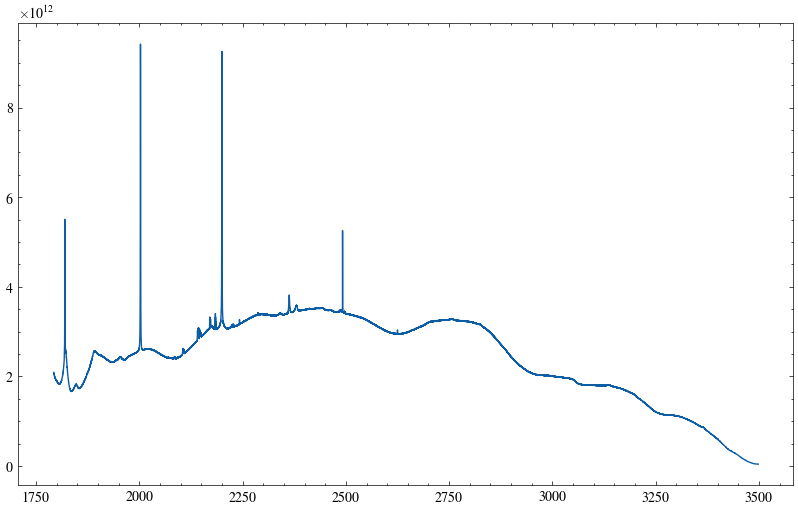

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(frequency_mhz, mean_spectrum)

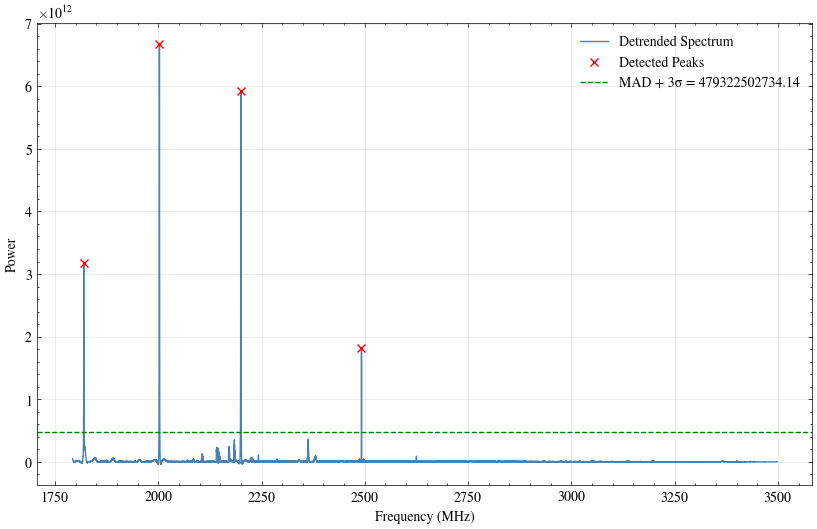

In [8]:
# perfom the time average and peak ideintification

spectrum_corrected = base_correction(frequency_mhz, mean_spectrum)

# Peak detection

sigma_value_high = 3
    # Detect peaks
threshold_high = MAD(spectrum_corrected) + sigma_value_high * np.std(spectrum_corrected)
peaks, properties = find_peaks(spectrum_corrected,
                                height=threshold_high,
                                prominence=0.5,
                                distance=80
                                )


plt.figure(figsize=(10, 6))
plt.plot(frequency_mhz, spectrum_corrected, label='Detrended Spectrum', color='steelblue')
plt.plot(frequency_mhz[peaks], spectrum_corrected[peaks], 'rx', label='Detected Peaks', markersize=6)
plt.axhline(threshold_high, color='green', linestyle='--', label=f'MAD + 3σ = {threshold_high:.2f}')
plt.xlabel("Frequency (MHz)")
plt.ylabel("Power")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)


In [9]:
# define the FWHM

widths_idx, width_heights, left_ips, right_ips = peak_widths(
    spectrum_corrected, peaks, rel_height=0.5)

# frequency resolution
freq_resolution = frequency_mhz[1] - frequency_mhz[0]
fwhm_freq = widths_idx * freq_resolution



for i, pk in enumerate(peaks):
    print(f"Peak at {frequency_mhz[pk]:.4f} MHz | FWHM = {fwhm_freq[i]:.4f} MHz "
          f"| half-max level = {width_heights[i]:.4e}")

Peak at 1819.6278 MHz | FWHM = 0.4368 MHz | half-max level = 1.5757e+12
Peak at 2002.7828 MHz | FWHM = 0.6259 MHz | half-max level = 3.3197e+12
Peak at 2199.9302 MHz | FWHM = 0.6552 MHz | half-max level = 2.9460e+12
Peak at 2492.0063 MHz | FWHM = 0.0353 MHz | half-max level = 9.0465e+11


In [37]:
frequency_mhz.size

63877

In [36]:
freq_resolution*1000

n_channels = (frequency_mhz[-1] - frequency_mhz[0])/freq_resolution
n_channels

np.float64(63876.0)

In [10]:


# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum at ONE time step.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peaks_index": peak_index,
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} MHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} MHz")
        print(f"  End Frequency  : {end_freq:.4f} MHz")
        print(f"  Bandwidth      : {bandwidth:.4f} MHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label=f'Threshold = {threshold} ')
            plt.xlabel("Frequency [MHz]", fontsize=17)
            plt.ylabel("Detrended Power", fontsize=17)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} MHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()


    return results_outliers


Outlier 1:
  Peak Frequency : 1819.6278 MHz
  Peak Power     : 3168865687617.8301 dB
  Start Frequency: 1816.3700 MHz
  End Frequency  : 1826.9978 MHz
  Bandwidth      : 10.6277 MHz
  Corrupted Ch.  : 398 channels

Outlier 2:
  Peak Frequency : 2002.7828 MHz
  Peak Power     : 6670185580899.4863 dB
  Start Frequency: 2000.3529 MHz
  End Frequency  : 2004.8923 MHz
  Bandwidth      : 4.5395 MHz
  Corrupted Ch.  : 170 channels

Outlier 3:
  Peak Frequency : 2199.9302 MHz
  Peak Power     : 5925452067040.1094 dB
  Start Frequency: 2197.3400 MHz
  End Frequency  : 2202.1732 MHz
  Bandwidth      : 4.8332 MHz
  Corrupted Ch.  : 181 channels

Outlier 4:
  Peak Frequency : 2492.0063 MHz
  Peak Power     : 1816093130718.0786 dB
  Start Frequency: 2490.9649 MHz
  End Frequency  : 2493.1278 MHz
  Bandwidth      : 2.1629 MHz
  Corrupted Ch.  : 81 channels


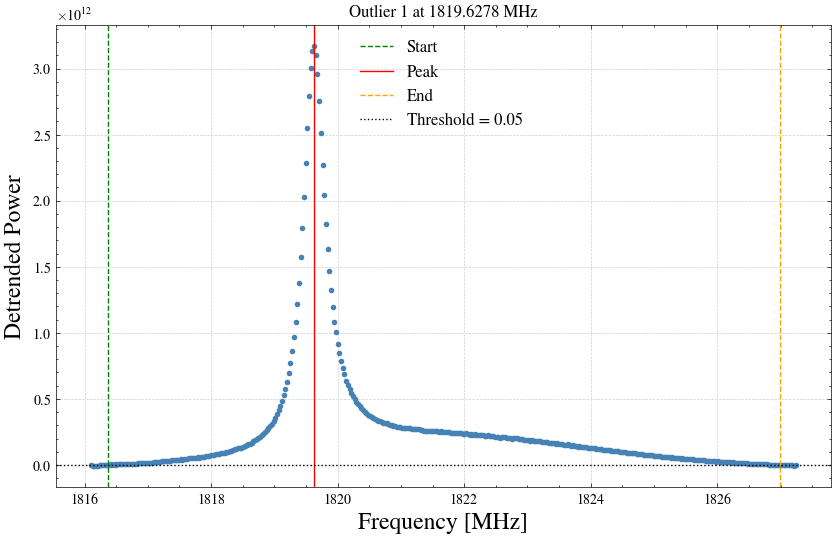

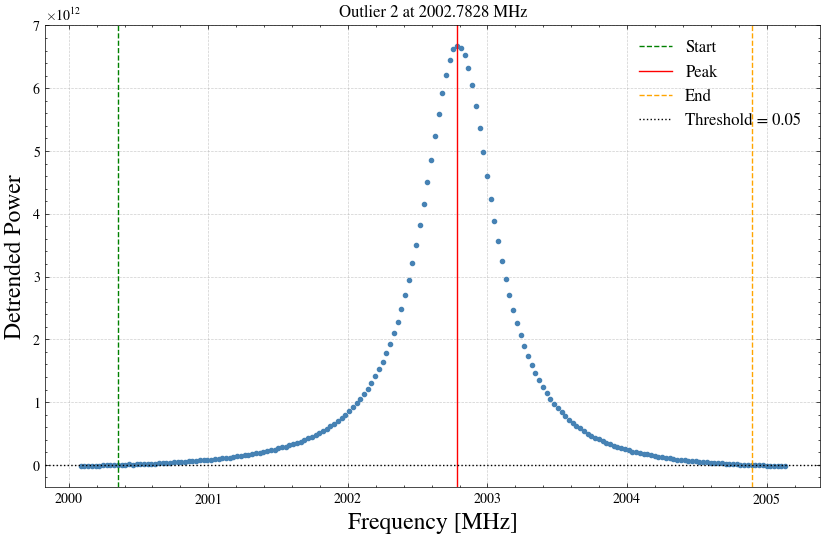

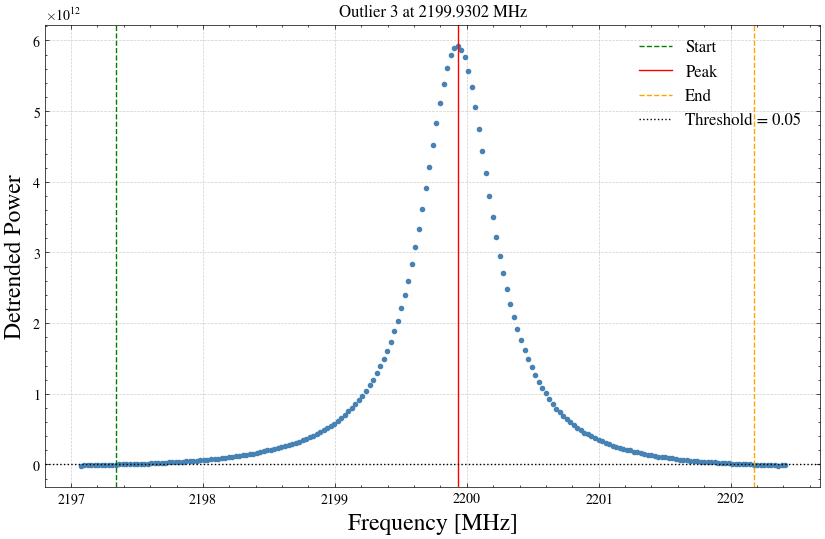

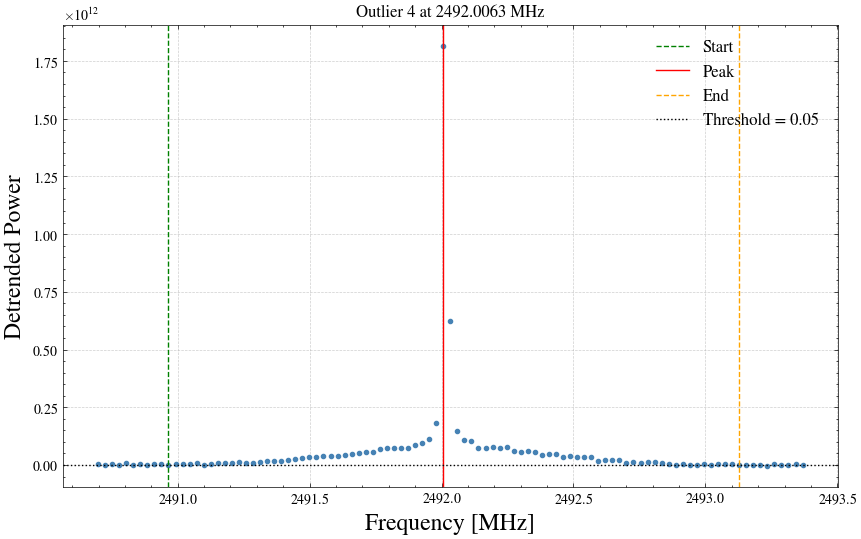

In [11]:
windows_df = quantify_all_outliers(frequency_mhz, spectrum_corrected, frequency_mhz[peaks], plot=True,
)

In [12]:
windows_df = pd.DataFrame(windows_df)
windows_df

,peaks_index,peak_freq,peak_power,start_freq,end_freq,bandwidth,n_channels
0,1008,1819.627762,3.168866e+12,1816.370010,1826.997757,10.627747,398
1,7867,2002.782822,6.670186e+12,2000.352859,2004.892349,4.539490,170
2,15250,2199.930191,5.925452e+12,2197.340012,2202.173233,4.833221,181
3,26188,2492.006302,1.816093e+12,2490.964890,2493.127823,2.162933,81


In [13]:

def obw_99(
    freq,
    power,
    peak_freqs,
    threshold=0.05,
    obw_percentage=99,
    plot=True
):
    """
    For every frequency listed in "peak_freq", compute:

    1. Occupied Bandwidth (OBW) based on the specified percentage of integrated power.
    2. FWHM (Full Width at Half Maximum) based on the peak height. The width of the peak at half
       its prominence above the local baseline, computed via 
       `scipy.signal.peak_widths` with `rel_height=0.5`.

    Parameters
    ----------
    freq : 1D array
        Frequency array in GHz.
    power : 1D array
        Linear, background-subtracted power spectrum.
    peak_freqs : list or array
        Detected peak frequencies in GHz.
    threshold : float
        Linear-power threshold used to identify feature boundaries.
    obw_percentage : float
        Percentage of integrated power used for OBW, usually 99.
    plot : bool
        Plot each feature and its OBW boundaries.

    Returns
    -------
    results_outliers : list of dict
        Measurements for each detected feature.
    """

    freq = np.asarray(freq, dtype=float)
    power = np.asarray(power, dtype=float)
    peak_freqs = np.asarray(peak_freqs, dtype=float)
    freq_resolution = freq[1] - freq[0]

    if freq.ndim != 1 or power.ndim != 1:
        raise ValueError("freq and power must be 1D arrays.")

    if len(freq) != len(power) or len(freq) < 2:
        raise ValueError("freq and power must have equal length >= 2.")

    if not np.all(np.isfinite(freq)) or not np.all(np.isfinite(power)):
        raise ValueError("freq and power must contain finite values.")

    if not 0 < obw_percentage < 100:
        raise ValueError("obw_percentage must be between 0 and 100.")

    # Sort by frequency to ensure correct integration
    order = np.argsort(freq)
    freq = freq[order]
    power = power[order]

    if np.any(np.diff(freq) <= 0):
        raise ValueError("Frequency values must be unique.")

    # -----------------------------------------------------------------
    # Convert peak frequencies -> nearest array indices (needed for
    # peak_widths, which operates on integer index positions)
    # -----------------------------------------------------------------
    peak_indices = np.array(
        [np.argmin(np.abs(freq - pf)) for pf in peak_freqs]
    )
 
    # -----------------------------------------------------------------
    # FWHM for ALL peaks at once (vectorised call, rel_height=0.5 =>
    # half-maximum relative to each peak's own prominence)
    # -----------------------------------------------------------------
    widths_idx, width_heights, left_ips, right_ips = peak_widths(
        power, peak_indices, rel_height=0.5
    )
    fwhm_freq = widths_idx * freq_resolution

    # -----------------------------------------------------------------
    # Sanity check: a zero-width / zero-prominence result means the
    # supplied peak_freqs did not line up with a true local maximum in
    # `power` (e.g. peak_freqs came from a different array/step than
    # the one passed in here). Warn loudly rather than silently
    # returning a meaningless FWHM of 0.
    # -----------------------------------------------------------------
    # for i, w in enumerate(widths_idx):
    #     if w == 0:
    #         warnings.warn(
    #             f"Peak at {peak_freqs[i]:.4f} MHz has zero FWHM/prominence. "
    #             "This usually means peak_freqs was not derived from "
    #             "find_peaks(power, ...) on this same array. Pass the "
    #             "find_peaks indices/frequencies directly to avoid this.",
    #             RuntimeWarning,
    #         )
 
    idx_axis = np.arange(len(freq))
    fwhm_left_freq = np.interp(left_ips, idx_axis, freq)
    fwhm_right_freq = np.interp(right_ips, idx_axis, freq)
 

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # 1. Find the channel nearest to the detected peak
        peak_index = np.argmin(np.abs(freq - peak_f))

        # 2. Walk left until the power falls to the threshold
        left_index = peak_index

        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        # 3. Walk right until the power falls to the threshold
        right_index = peak_index

        while (
            right_index < len(power) - 1
            and power[right_index] > threshold
        ):
            right_index += 1

        start_freq = freq[left_index]
        end_freq = freq[right_index]

        # Threshold-based bandwidth
        bandwidth = end_freq - start_freq

        # Number of channels in the selected interval
        n_channels = right_index - left_index + 1

        peak_power = power[peak_index]

        # 4. Extract the spectrum belonging to this feature
        f_local = freq[left_index:right_index + 1]
        p_local = power[left_index:right_index + 1]

        # Clip negative residuals to zero for power integration
        # (relevant if baseline subtraction created negative values)
        p_local = np.clip(p_local, 0, None)

        # 5. Integrate the linear power over frequency
        df_local = np.diff(f_local)

        segment_power = (
            0.5 * (p_local[:-1] + p_local[1:]) * df_local
        )

        cumulative_power = np.concatenate((
            [0.0],
            np.cumsum(segment_power)
        ))

        total_power = cumulative_power[-1]

        if total_power > 0:
            # Normalize cumulative power to run from 0 to 1
            cumulative_fraction = cumulative_power / total_power

            # Equal power is excluded from both tails
            tail_fraction = (1 - obw_percentage / 100) / 2

            # 6. Find lower and upper OBW boundaries
            obw_start = np.interp(
                tail_fraction,
                cumulative_fraction,
                f_local
            )

            obw_end = np.interp(
                1 - tail_fraction,
                cumulative_fraction,
                f_local
            )

            obw = obw_end - obw_start

        else:
            # No positive integrated power within the feature
            obw_start = np.nan
            obw_end = np.nan
            obw = np.nan

        # Spectral bandwidth ratio
        R_obw_fwhm = obw / fwhm_freq[i] * 1000 if fwhm_freq[i] != 0 else np.nan


        # 7. Save the measurements
        result = {
            "peak_index": peak_index,
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "threshold_bandwidth": bandwidth,
            "n_channels": n_channels,
            # "obw_start_freq": obw_start,
            # "obw_end_freq": obw_end,
            "obw_99": obw,
            "integrated_power": total_power,
            "fwhm_mhz": fwhm_freq[i],
            "fwhm_khz": fwhm_freq[i] * 1e3,
            # "fwhm_left_freq_mhz": fwhm_left_freq[i],
            # "fwhm_right_freq_mhz": fwhm_right_freq[i],
            # "fwhm_half_max_power": width_heights[i],
            "R_obw_fwhm": R_obw_fwhm
        }

        results_outliers.append(result)

        # 8. Display results
        print(f"\nOutlier {i + 1}:")
        print(f"  Peak frequency       : {freq[peak_index]:.2f} MHz")
        print(f"  Peak linear power    : {peak_power:.2g}")
        print(f"  Threshold start      : {start_freq:.2f} MHz")
        print(f"  Threshold end        : {end_freq:.2f} MHz")
        print(f"  Threshold bandwidth  : {bandwidth * 1000:.2f} kHz")
        print(f"  Channels             : {n_channels}")
        print(f"  FWHM                 : {fwhm_freq[i] * 1000:.2f} kHz")

        if np.isfinite(obw):
            print(f"  OBW lower boundary   : {obw_start:.2f} MHz")
            print(f"  OBW upper boundary   : {obw_end:.2f} MHz")
            print(f"  OBW ({obw_percentage}%)        : {obw * 1000:.2f} kHz")
        else:
            print("  OBW                  : Undefined (zero integrated power)")

        print(f"  R_obw_fwhm            : {R_obw_fwhm:.2f} ")


        # 9. Plot the feature and both sets of boundaries
        if plot:
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad + 1, len(freq))

            plt.figure(figsize=(8, 5))

            plt.plot(freq[lo:hi], power[lo:hi], 
                     color="0.35", label="Detrended Signal")
            
            plt.plot(freq[peak_index], peak_power, "ro", 
                     label="Peak frequency")

            plt.axvline(start_freq, color="green", linestyle="--",
                        label="Start frequency")
            
            plt.axvline(end_freq, color="orange", linestyle="--",
                        label="End frequency")
           
            plt.axhline(threshold, color="black", linestyle=":",
                        label=f"Threshold = {threshold}")

             # FWHM span (half-max, from peak_widths)
            plt.hlines(
                width_heights[i], fwhm_left_freq[i], fwhm_right_freq[i],
                color="darkorange", lw=2, label=f"FWHM: {fwhm_freq[i]*1e3:.2f} kHz"
            )
            # plt.vlines(
            #     [fwhm_left_freq[i], fwhm_right_freq[i]],
            #     ymin=power[lo:hi].min(), ymax=width_heights[i],
            #     color="gray", linestyle="--", lw=0.8
            # )
 
           
            if np.isfinite(obw):

                # Shade Simulated Occupied Bandwidth (Crimson)
                plt.axvspan(
                        obw_start,
                        obw_end,
                        color="purple",
                        alpha=0.12,
                        label=f"{obw_percentage}% OBW: {obw * 1000:.2f} kHz",
                    )

                # plt.axvline(obw_start, color="purple", linestyle="-.",
                #             label=f"{obw_percentage}% OBW boundaries")
                # plt.axvline(obw_end, color="purple", linestyle="-.")

            plt.xlabel("Frequency [MHz]", fontsize=16)
            plt.ylabel("Power [counts]", fontsize=16)
            plt.title(f"RFI feature at {freq[peak_index]:.2f} MHz", fontsize=16)
            plt.grid(True, linestyle="--", alpha=0.5)
            plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=17)


    return results_outliers


In [14]:

 
# Colours assigned to each dB level (colourblind-friendly)
_LEVEL_COLOURS = {3: "#1f77b4", 10: "#ff7f0e", 20: "#2ca02c", 30: "#d62728"}
 
 
def calculate_xdb_bandwidths(
    freq,
    power,
    peak_index,
    start_index,
    end_index,
    threshold=0.05,
    levels=(3, 10, 20, 30),
    plot=False,
    ax=None,
    freq_unit=None,
    power_unit=None,
    title=None,
):
    """
    Calculate multiple x-dB bandwidths for ONE RFI peak.
 
    Parameters
    ----------
    freq        : 1-D array   Frequency array (GHz or MHz — consistent units).
    power       : 1-D array   Detrended power spectrum (dB); background ≈ 0.
    peak_index  : int         Index of the peak in the full arrays.
    start_index : int         Left threshold-crossing index (from outer walk).
    end_index   : int         Right threshold-crossing index.
    threshold   : float       Background threshold used by the outer walk
                              (kept for API compatibility; not used for x-dB).
    levels      : tuple       dB drops to evaluate (default: 3, 10, 20, 30).
    plot        : bool        If True, produce a diagnostic plot.
    ax          : matplotlib.axes.Axes or None
                              Axes to draw on.  A new figure is created when
                              None (only used when plot=True).
    freq_unit   : str         Label for the frequency axis (default "GHz").
    title       : str or None Optional plot title.
 
    Returns
    -------
    results : dict
        For each level N: ``B{N}_start``, ``B{N}_end``, ``B{N}`` (bandwidth).
        Values are NaN when the level is not reached on either side.
    ax : matplotlib.axes.Axes  (only when plot=True)
        The axes object so the caller can further customise or save the figure.
    """
    freq  = np.asarray(freq,  dtype=float)
    power = np.asarray(power, dtype=float)
 
    peak_power = float(power[peak_index])
    results    = {}
 
    # Nothing to measure if the peak is at or below the background
    if peak_power <= 0:
        for x_db in levels:
            results[f"B{x_db}_start"] = np.nan
            results[f"B{x_db}_end"]   = np.nan
            results[f"B{x_db}"]       = np.nan
        if plot:
            ax = _make_plot(freq, power, peak_index, start_index, end_index,
                            results, levels, freq_unit, title, ax)
            return results, ax
        return results
 
    for x_db in levels:
        target = peak_power - x_db      # absolute dB level we are looking for
 
        # ── Walk LEFT from peak until power ≤ target ──────────────────────
        left = peak_index
        while left > 0 and power[left] > target:
            left -= 1
 
        # ── Walk RIGHT from peak until power ≤ target ────────────────────
        right = peak_index
        while right < len(power) - 1 and power[right] > target:
            right += 1
 
        # ── Check whether the level was actually reached ──────────────────
        left_reached  = power[left]  <= target
        right_reached = power[right] <= target
 
        if not left_reached or not right_reached:
            f_low     = np.nan
            f_high    = np.nan
            bandwidth = np.nan
 
        else:
            # ── Sub-channel interpolation (left side) ─────────────────────
            # Crossing is between indices `left` (below target) and
            # `left + 1` (above target).
            p0, p1 = power[left], power[left + 1]
            f0, f1 = freq[left],  freq[left + 1]
            f_low  = f0 + (target - p0) * (f1 - f0) / (p1 - p0) \
                     if p1 != p0 else (f0 + f1) / 2.0
 
            # ── Sub-channel interpolation (right side) ────────────────────
            # Crossing is between indices `right - 1` (above target) and
            # `right` (below target).
            p0, p1 = power[right - 1], power[right]
            f0, f1 = freq[right - 1],  freq[right]
            f_high = f0 + (target - p0) * (f1 - f0) / (p1 - p0) \
                     if p1 != p0 else (f0 + f1) / 2.0
 
            bandwidth = f_high - f_low
 
        # ── Store results for this level ──────────────────────────────────
        results[f"B{x_db}_start"] = f_low
        results[f"B{x_db}_end"]   = f_high
        results[f"B{x_db}"]       = bandwidth
 
    if plot:
        ax = _make_plot(freq, power, peak_index, start_index, end_index,
                        results, levels, freq_unit,power_unit, title, ax)
        return results, ax
 
    return results
 


Outlier 1:
  Peak frequency       : 1819.63 MHz
  Peak linear power    : 3.2e+12
  Threshold start      : 1816.37 MHz
  Threshold end        : 1827.00 MHz
  Threshold bandwidth  : 10627.75 kHz
  Channels             : 399
  FWHM                 : 436.76 kHz
  OBW lower boundary   : 1817.39 MHz
  OBW upper boundary   : 1825.86 MHz
  OBW (99%)        : 8476.60 kHz
  R_obw_fwhm            : 19407.99 

Outlier 2:
  Peak frequency       : 2002.78 MHz
  Peak linear power    : 6.7e+12
  Threshold start      : 2000.35 MHz
  Threshold end        : 2004.89 MHz
  Threshold bandwidth  : 4539.49 kHz
  Channels             : 171
  FWHM                 : 625.90 kHz
  OBW lower boundary   : 2001.08 MHz
  OBW upper boundary   : 2004.27 MHz
  OBW (99%)        : 3192.41 kHz
  R_obw_fwhm            : 5100.49 

Outlier 3:
  Peak frequency       : 2199.93 MHz
  Peak linear power    : 5.9e+12
  Threshold start      : 2197.34 MHz
  Threshold end        : 2202.17 MHz
  Threshold bandwidth  : 4833.22 kHz
  Cha

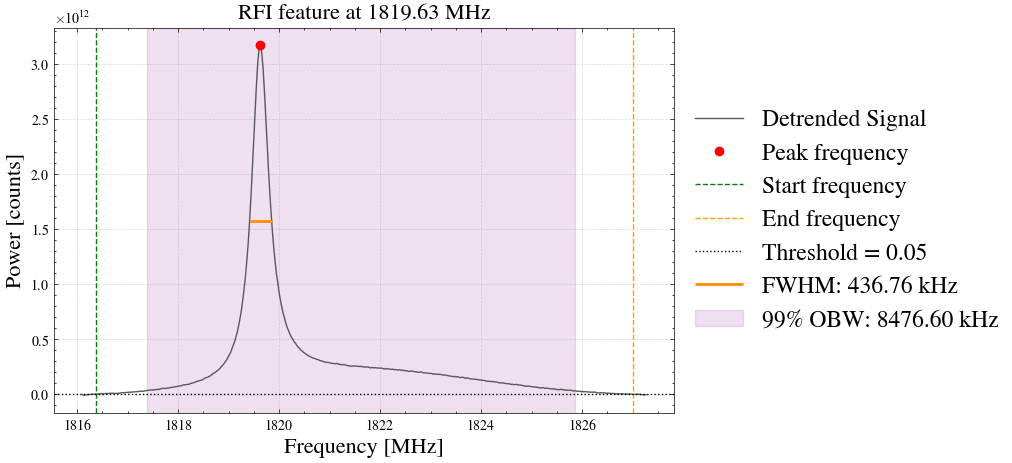

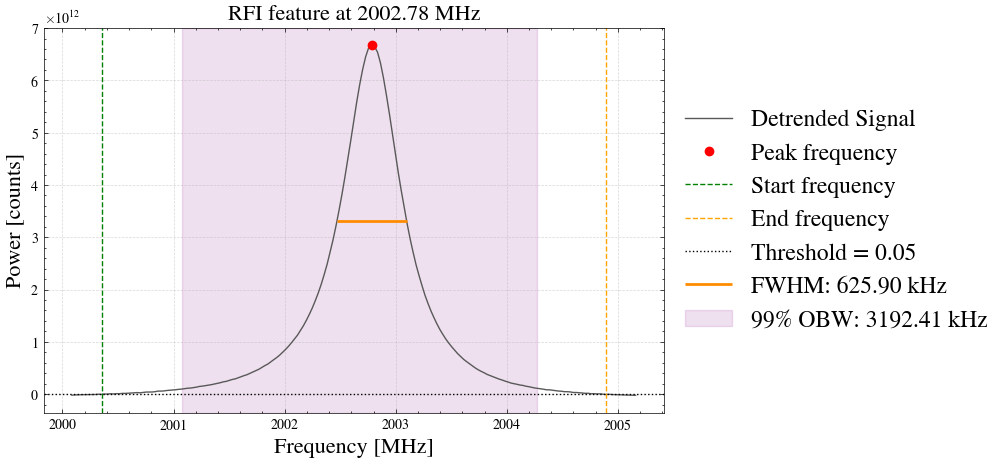

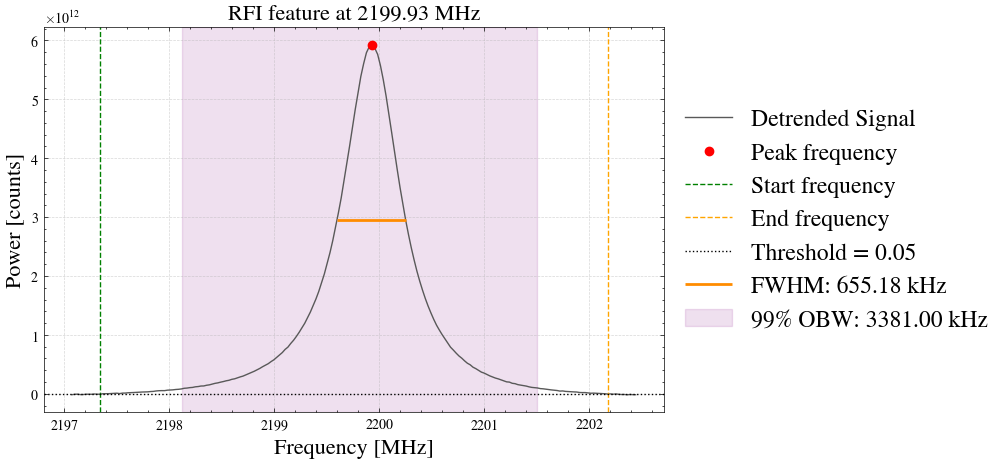

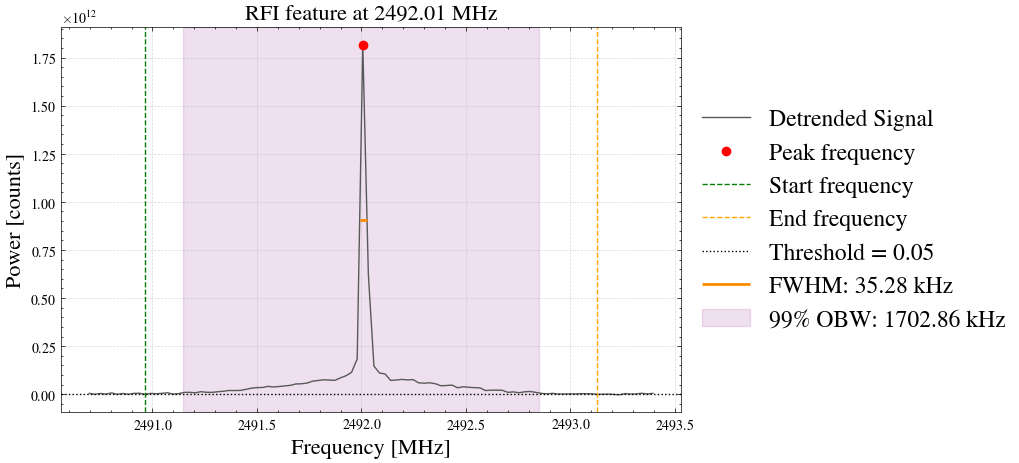

In [15]:
results = obw_99(
    freq=frequency_mhz,
    power=spectrum_corrected,
    peak_freqs=frequency_mhz[peaks],
    threshold=0.05,
    obw_percentage=99,
    plot=True
)

In [16]:
results_obw_99_df = pd.DataFrame(results)
results_obw_99_df

,peak_index,peak_freq,peak_power,start_freq,end_freq,threshold_bandwidth,n_channels,obw_99,integrated_power,fwhm_mhz,fwhm_khz,R_obw_fwhm
0,1008,1819.627762,3.168866e+12,1816.370010,1826.997757,10.627747,399,8.476603,2.998392e+12,0.436759,436.758531,19407.985374
1,7867,2002.782822,6.670186e+12,2000.352859,2004.892349,4.539490,171,3.192414,5.507852e+12,0.625903,625.903365,5100.490005
2,15250,2199.930191,5.925452e+12,2197.340012,2202.173233,4.833221,182,3.381005,5.128037e+12,0.655178,655.177736,5160.438705
3,26188,2492.006302,1.816093e+12,2490.964890,2493.127823,2.162933,82,1.702865,1.442209e+11,0.035285,35.284548,48260.923653


In [17]:
# results = obw_99(
#     freq=frequency_mhz ,  
#     power=spectrum_corrected,
#     peak_freqs=frequency_mhz[peaks],      
#     threshold=0.05,
#     obw_percentage=99,
#     plot=True
# )

## Calculate the 10, 20, and 30 dB

We will have to convert the Power [counts] to Power [dB] -(which is to rescale to Log format)

In [18]:
# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)

mean_spectrum_db_corrected = base_correction(frequency_mhz, mean_spectrum_db)

In [19]:
for i, peak in enumerate(peaks):

    # Peak channel index
    peak_index = int(peak)

    # Start and end frequencies for this peak (MHz)
    start_freq = windows_df["start_freq"].iloc[i]
    end_freq = windows_df["end_freq"].iloc[i]

    # Convert boundary frequencies to channel indices
    start_index = int(np.argmin(np.abs(frequency_mhz - start_freq)))
    end_index = int(np.argmin(np.abs(frequency_mhz - end_freq)))

    xdb_results = calculate_xdb_bandwidths(
        freq=frequency_mhz,
        power=mean_spectrum_db_corrected,
        peak_index=peak_index,
        start_index=start_index,
        end_index=end_index,
        levels=(3, 10, 20, 30),
        freq_unit="MHz",
        power_unit="dB",
        
    )

    print(f"\nPeak {i + 1}: {frequency_mhz[peak_index]:.2f} MHz")
    for level in (3, 10, 20, 30):
        print(f"  B{level}: {xdb_results[f'B{level}']:.2f} MHz")


Peak 1: 1819.63 MHz
  B3: 0.43 MHz
  B10: nan MHz
  B20: nan MHz
  B30: nan MHz

Peak 2: 2002.78 MHz
  B3: 0.52 MHz
  B10: 2.15 MHz
  B20: nan MHz
  B30: nan MHz

Peak 3: 2199.93 MHz
  B3: 0.59 MHz
  B10: nan MHz
  B20: nan MHz
  B30: nan MHz

Peak 4: 2492.01 MHz
  B3: 0.07 MHz
  B10: nan MHz
  B20: nan MHz
  B30: nan MHz


In [20]:
"""
calculate_local_snr.py
======================
Local SNR for RFI peaks in a detrended power spectrum.

Why local?
----------
The raw spectrum has a large, varying baseline (receiver bandpass + sky).
Noise fluctuations scale with that baseline, so a global noise estimate
gives wrong SNR values for peaks in bright vs quiet parts of the band.
Solution: for each peak, estimate the noise ONLY from channels adjacent to
that peak — same local baseline character, but outside the RFI window.

Input: the DETRENDED spectrum (background ≈ 0) and the peak locations
       produced by your existing pipeline.
"""



def calculate_local_snr(
    freq,
    power_detrended,
    peak_index,
    start_index,
    end_index,
    window_factor=5,
    noise_guard=5,
    min_noise_bins=20,
    plot=False,
    ax=None,
    freq_unit=None,
    power_unit=None

):
    """
    Compute peak and integrated SNR using a LOCAL noise estimate.

    The noise is sampled from the detrended channels that are:
      * inside the local window  [peak − W, peak + W]  (W = window_factor × feature half-width)
      * but OUTSIDE the feature  [start − guard, end + guard]

    This ensures the noise reflects the local background character of each
    individual peak rather than a global (and therefore biased) estimate.

    Parameters
    ----------
    freq             : 1-D array  Frequency axis (MHz or GHz).
    power_detrended  : 1-D array  Detrended linear power (background ≈ 0).
    peak_index       : int        Index of the peak.
    start_index      : int        Left edge of the feature.
    end_index        : int        Right edge of the feature.
    window_factor    : float      Half-width of local noise window in units of
                                  feature half-widths.  Default 5.
    noise_guard      : int        Extra channels to skip on each side of the
                                  feature before sampling noise.  Default 5.
    min_noise_bins   : int        Minimum off-feature bins required; raises
                                  ValueError if the window is too narrow.
    plot             : bool       Produce a diagnostic plot.
    ax               : Axes|None  Axes to draw on (created when None).
    freq_unit        : str        Axis label (default "MHz").
    title            : str|None   Optional plot title.

    Returns
    -------
    results : dict
        ``sigma_local``       Local noise std (linear power units).
        ``peak_excess``       Peak detrended power (above local mean).
        ``local_mean``        Mean of local off-feature channels (should ≈ 0).
        ``snr_peak``          peak_excess / sigma_local  (dimensionless).
        ``snr_peak_db``       10·log₁₀(snr_peak)  [dB].
        ``integrated_power``  Σ clipped detrended power inside feature.
        ``snr_integrated``    integrated_power / (sigma_local · √N_signal).
        ``snr_integrated_db`` 10·log₁₀(snr_integrated)  [dB].
        ``snr_ratio``         snr_integrated / snr_peak  (shape indicator).
        ``n_signal_bins``     Channels inside [start, end].
        ``n_noise_bins``      Off-feature channels used for noise estimate.
        ``noise_window``      (win_lo, win_hi) indices of the local window.
    ax : Axes  (only when plot=True)
    """
    freq  = np.asarray(freq,  dtype=float)
    power = np.asarray(power_detrended, dtype=float)
    n     = len(power)

    # ── Local noise window ────────────────────────────────────────────────
    feature_hw  = max(1, (end_index - start_index) // 2)
    W           = int(window_factor * feature_hw)
    win_lo      = max(0,  peak_index - W)
    win_hi      = min(n,  peak_index + W + 1)

    excl_lo     = max(win_lo, start_index - noise_guard)
    excl_hi     = min(win_hi, end_index   + 1 + noise_guard)

    left_noise  = power[win_lo  : excl_lo]
    right_noise = power[excl_hi : win_hi ]
    local_noise = np.concatenate([left_noise, right_noise])

    if len(local_noise) < min_noise_bins:
        raise ValueError(
            f"Only {len(local_noise)} off-feature bins in the local window "
            f"[{win_lo}, {win_hi}]. Increase window_factor or reduce noise_guard."
        )

    local_mean  = float(np.median(local_noise))   # median is robust to tails
    sigma_local = float(np.std(local_noise - local_mean))

    # ── Signal metrics ────────────────────────────────────────────────────
    peak_excess = float(power[peak_index]) - local_mean

    sig         = power[start_index : end_index + 1] - local_mean
    sig_clipped = np.maximum(sig, 0.0)             # no negative "signal"
    integrated_power = float(np.sum(sig_clipped))
    n_signal    = len(sig)

    # ── SNR ───────────────────────────────────────────────────────────────
    snr_peak = (peak_excess / sigma_local
                if sigma_local > 0 else np.nan)
    snr_integrated = (integrated_power / (sigma_local * np.sqrt(n_signal))
                      if sigma_local > 0 else np.nan)

    # snr_peak_db       = (10.0 * np.log10(snr_peak)
    #                      if (snr_peak is not np.nan and snr_peak > 0) else np.nan)
    # snr_integrated_db = (10.0 * np.log10(snr_integrated)
    #                      if (snr_integrated is not np.nan and snr_integrated > 0)
    #                      else np.nan)
    snr_ratio = (snr_integrated / snr_peak
                 if (snr_peak and snr_integrated and snr_peak > 0) else np.nan)

    results = {
        "peak_frequency":     freq[peak_index],
        "sigma_local":       sigma_local,
        "peak_excess":       peak_excess,
        "local_mean":        local_mean,
        "snr_peak":          snr_peak,
        #"snr_peak_db":       snr_peak_db,
        "integrated_power":  integrated_power,
        "snr_integrated":    snr_integrated,
        #"snr_integrated_db": snr_integrated_db,
        "snr_ratio":         snr_ratio,
        "n_signal_bins":     n_signal,
        "n_noise_bins":      len(local_noise),
        "noise_window":      (win_lo, win_hi),
    }

    if plot:
        ax = _make_plot(freq, power, peak_index, start_index, end_index,
                        win_lo, win_hi, excl_lo, excl_hi,
                        local_mean, sigma_local, results,
                        freq_unit,power_unit, ax)
        return results, ax

    return results


# ─────────────────────────────────────────────────────────────────────────────
# Batch helper — call once for every peak returned by your pipeline
# ─────────────────────────────────────────────────────────────────────────────

# def calculate_snr_all_peaks(
#     freq,
#     power_detrended,
#     peaks,
#     window_factor=5,
#     noise_guard=5,
# ):
#     """
#     Calculate local SNR for every peak in a list.

#     Parameters
#     ----------
#     peaks : list of dict
#         Each dict must have keys ``peak_index``, ``start_index``, ``end_index``
#         (as produced by your existing quantify_all_outliers pipeline).

#     Returns
#     -------
#     list of dict — one per peak; each is the results dict from
#     ``calculate_local_snr`` augmented with the input peak keys.
#     """
#     out = []
#     for pk in peaks:
#         try:
#             res = calculate_local_snr(
#                 freq, power_detrended,
#                 peak_index=pk["peak_index"],
#                 start_index=pk["start_index"],
#                 end_index=pk["end_index"],
#                 window_factor=window_factor,
#                 noise_guard=noise_guard,
#             )
#         except ValueError as e:
#             res = {"error": str(e)}
#         out.append({**pk, **res})
#     return out


# ─────────────────────────────────────────────────────────────────────────────
# Plot
# ─────────────────────────────────────────────────────────────────────────────

def _make_plot(freq, power, peak_index, start_index, end_index,
               win_lo, win_hi, excl_lo, excl_hi,
               local_mean, sigma_local, results,
               freq_unit, power_unit, ax):


    
    import matplotlib.patches as mpatches

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    else:
        fig = ax.get_figure()

    f_win = freq[win_lo:win_hi]
    p_win = power[win_lo:win_hi]

    # ── Full local window ─────────────────────────────────────────────────
    ax.plot(f_win, p_win, color="#0A0A0A", lw=1.2, zorder=3,
            label="Detrended power")

    # ── Noise regions (shaded) ────────────────────────────────────────────
    if excl_lo > win_lo:
        ax.axvspan(freq[win_lo], freq[excl_lo - 1],
                   color="#0072B2", alpha=0.4, zorder=1)
    if excl_hi < win_hi:
        ax.axvspan(freq[excl_hi], freq[win_hi - 1],
                   color="#0072B2", alpha=0.4, zorder=1)

    # ── Feature region ────────────────────────────────────────────────────
    ax.axvspan(freq[start_index], freq[end_index],
               alpha=0.10, color="#D62728", zorder=1)

    # ── Noise level lines ─────────────────────────────────────────────────
    ax.axhline(local_mean, color="#0A0A0A", lw=1.2, ls="--",
               label=f"Local mean  ({local_mean:.2f})")
    ax.axhline(local_mean + sigma_local, color="#EE0909", lw=1.0, ls="-.",
               alpha=0.85, label=f"+1σ  ({sigma_local:.2f})")
    ax.axhline(local_mean - sigma_local, color="#009E73", lw=1.0, ls="-.",
               alpha=0.85, label=f"-1σ  (-{sigma_local:.2f})")

    # ── Peak ─────────────────────────────────────────────────────────────
    # ax.axvline(freq[peak_index], color="#D62728", lw=1.1, ls="-",
    #            label=f"Peak  {freq[peak_index]:.4f} {freq_unit}", zorder=4)
    # ax.scatter([freq[peak_index]], [power[peak_index]],
    #            color="#D62728", s=50, zorder=6)

    # ── Annotation box ────────────────────────────────────────────────────
    ann = (
        #f"Peak SNR       {results['snr_peak_db']:+.1f} dB\n"
        #f"Integrated SNR {results['snr_integrated_db']:+.1f} dB\n"
        f"SNR ratio      {results['snr_ratio']:.2f}\n"
        f"σ_local        {results['sigma_local']:.2f}\n"
        f"Signal bins    {results['n_signal_bins']}\n"
        f"Noise bins     {results['n_noise_bins']}"
    )
    ax.text(0.97, 0.97, ann, transform=ax.transAxes,
            ha="right", va="top", fontsize=8.5, family="monospace",
            bbox=dict(boxstyle="round,pad=0.45", fc="white",
                      ec="0.7", alpha=0.92))

    # ── Legend patches for shading ────────────────────────────────────────
    sig_patch = mpatches.Patch(color="#D55E00", alpha=0.4, label="RFI feature")   # Vermilion / Orange-Red
    noi_patch = mpatches.Patch(color="#0072B2", alpha=0.4, label="Noise sample")   # Deep Blue

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles=handles + [sig_patch, noi_patch],
              fontsize=8.5, loc="upper left", framealpha=0.85)

    ax.set_xlabel(f"Frequency [{freq_unit}]", fontsize=16)
    ax.set_ylabel(f"Detrended power [{power_unit}] ", fontsize=16)
    ax.set_title(f"Local SNR: {freq[peak_index]:.2f}", fontsize=16)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=17)
    #ax.set_xlim(float(f_win[0]), float(f_win[-1]))

    # y limits: show noise band clearly + a bit above peak
    p_peak = float(power[peak_index])
    # ax.set_ylim(local_mean - 4 * sigma_local,
    #             p_peak * 1.10)

    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.5)
    fig.tight_layout()
    return ax

In [21]:
# # SNR for linear power spectrum (detrended) using local noise estimate
# for i, peak in enumerate(peaks):

#     # Peak channel index
#     peak_index = int(peak)

#     # Start and end frequencies for this peak (MHz)
#     start_freq = windows_df["start_freq"].iloc[i]
#     end_freq = windows_df["end_freq"].iloc[i]

#     # Convert boundary frequencies to channel indices
#     start_index = int(np.argmin(np.abs(frequency_mhz - start_freq)))
#     end_index = int(np.argmin(np.abs(frequency_mhz - end_freq)))

#     snr = calculate_local_snr(
#         freq=frequency_mhz,
#         power_detrended=spectrum_corrected,
#         peak_index=peak_index,
#         start_index=start_index,
#         end_index=end_index)

        
#     # print(snr['snr_peak_db'])        # e.g. 25.3 dB — peak above local noise
#     # print(snr['snr_integrated_db'])  # e.g. 28.1 dB — total excess power
#     print(snr['snr_ratio'])          # e.g. 0.04  — low = spike, high = broad
#     print(snr['sigma_local'])        # local noise std (same units as your power)

#     # With a diagnostic plot:
#     snr, ax = calculate_local_snr(
#         freq=frequency_mhz,
#         power_detrended=spectrum_corrected,
#         peak_index=peak_index,
#         start_index=start_index,
#         end_index=end_index,
#         plot=True, freq_unit="MHz",
#         title=f"Peak at {frequency_mhz[peak]:.2f} MHz",
#     )


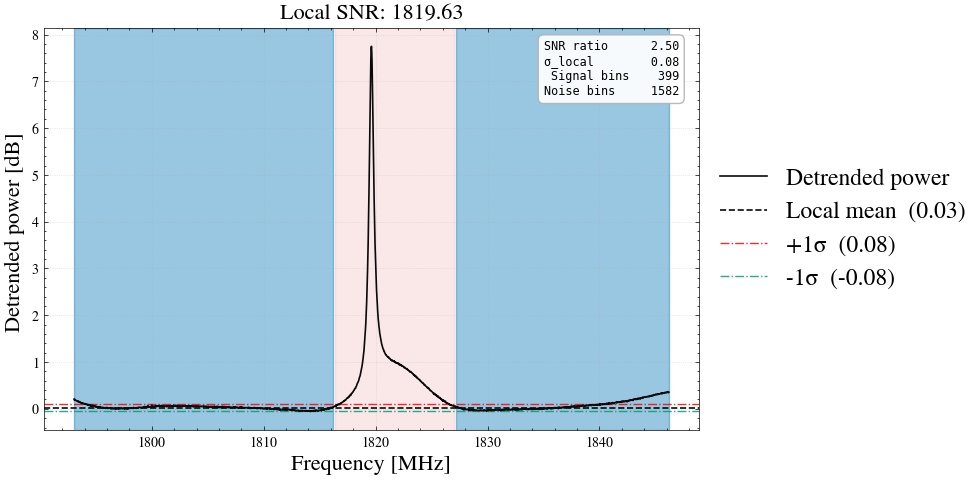

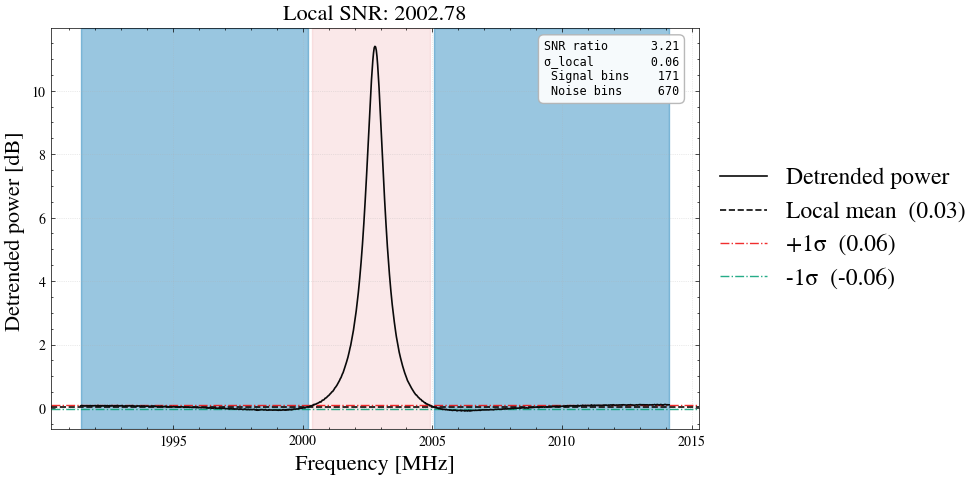

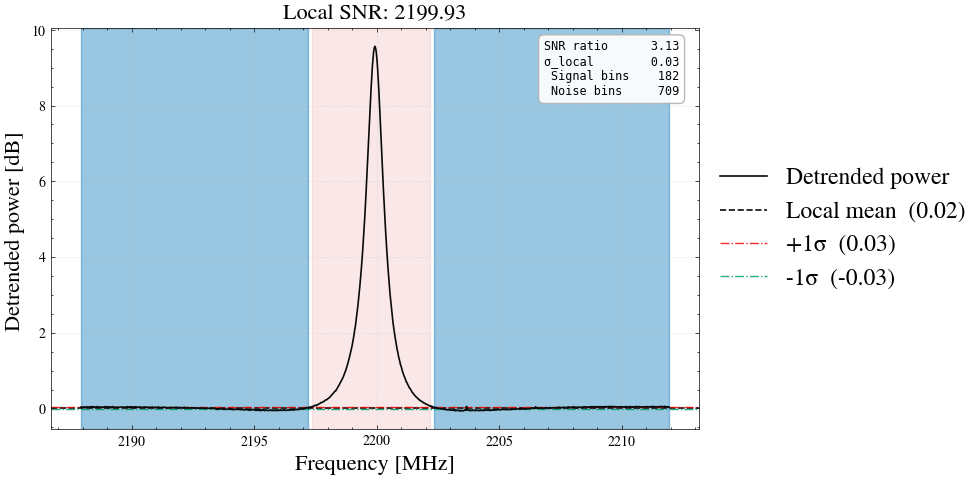

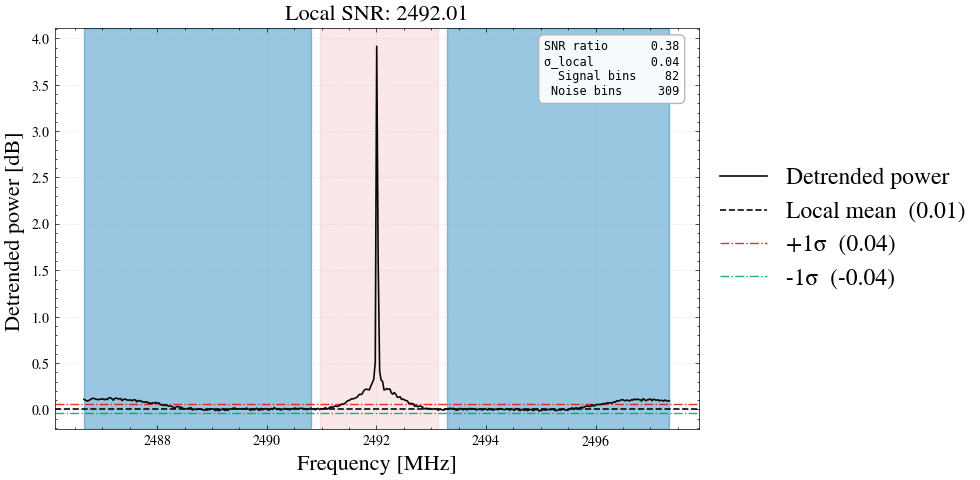

In [22]:
# determine SNR for the detrended mean spectrum (dB) rather than the raw linear spectrum
snr_results = []
for i, peak in enumerate(peaks):

    # Peak channel index
    peak_index = int(peak)

    # Start and end frequencies for this peak (MHz)
    start_freq = windows_df["start_freq"].iloc[i]
    end_freq = windows_df["end_freq"].iloc[i]

    # Convert boundary frequencies to channel indices
    start_index = int(np.argmin(np.abs(frequency_mhz - start_freq)))
    end_index = int(np.argmin(np.abs(frequency_mhz - end_freq)))

    # snr = calculate_local_snr(
    #     freq=frequency_mhz,
    #     power_detrended=mean_spectrum_db_corrected,
    #     peak_index=peak_index,
    #     start_index=start_index,
    #     end_index=end_index,
    #     plot=True, 
    #     freq_unit="MHz",
    #     power_unit="dB"
    #     )

        
   
    # print(snr['snr_ratio'])          # e.g. 0.04  — low = spike, high = broad
    # print(snr['sigma_local'])        # local noise std (same units as your power)

    # With a diagnostic plot:
    snr, ax = calculate_local_snr(
        freq=frequency_mhz,
        power_detrended=mean_spectrum_db_corrected,
        peak_index=peak_index,
        start_index=start_index,
        end_index=end_index,
        plot=True, 
        freq_unit="MHz",
        power_unit="dB"
    )

    snr_results.append(snr)


In [23]:
snr_results_df = pd.DataFrame(snr_results)
snr_results_df

,peak_frequency,sigma_local,peak_excess,local_mean,snr_peak,integrated_power,snr_integrated,snr_ratio,n_signal_bins,n_noise_bins,noise_window
0,1819.627762,0.083007,7.718399,0.028229,92.984754,385.792726,232.676265,2.502306,399,1582,"(13, 2004)"
1,2002.782822,0.058110,11.365271,0.031607,195.581133,477.203252,627.989691,3.210891,171,670,"(7442, 8293)"
2,2199.930191,0.034090,9.546186,0.016881,280.026111,403.094574,876.475769,3.129979,182,709,"(14800, 15701)"
3,2492.006302,0.044553,3.903905,0.009625,87.623255,13.435969,33.302911,0.380069,82,309,"(25988, 26389)"


In [24]:
"""
calculate_xdb_bandwidths.py
===========================
x-dB bandwidth calculator for a single RFI peak.

Accepts the power spectrum in EITHER scale:

    scale='db'     power is in dB    (background ≈ 0 dB after detrending,
                                       or any absolute dB level — only the
                                       DROP from the peak matters)

    scale='linear' power is in linear (background ≈ 0 after detrending;
                                       the threshold at each level is
                                       peak × 10^(−N/10), e.g. half the
                                       peak for the 3 dB point)

No conversion is performed.  Feed whichever scale you have.
The interpolated crossing frequencies — and therefore the bandwidths —
are identical in both cases (same physical threshold, two representations).
"""

_LEVEL_COLOURS = {3: "#1f77b4", 10: "#ff7f0e", 20: "#2ca02c", 30: "#d62728"}


# ─────────────────────────────────────────────────────────────────────────────
# Main function
# ─────────────────────────────────────────────────────────────────────────────

def calculate_xdb_bandwidths(
    freq,
    power,
    peak_index,
    start_index,
    end_index,
    threshold=0.05,
    levels=(10, 20, 30),
    scale="db",
    plot=False,
    ax=None,
    freq_unit="MHz",
    title=None,
):
    """
    Calculate x-dB bandwidths for one RFI peak.

    Parameters
    ----------
    freq        : 1-D array   Frequency array (consistent units).
    power       : 1-D array   Power spectrum — dB OR linear (see `scale`).
    peak_index  : int         Index of the peak.
    start_index : int         Left threshold-crossing index.
    end_index   : int         Right threshold-crossing index.
    threshold   : float       Kept for API compatibility; not used for x-dB.
    levels      : tuple       dB drops to evaluate. Default: (3, 10, 20, 30).
    scale       : str         'db'     — power is in dB; target = peak − N
                              'linear' — power is in linear; target = peak × 10^(−N/10)
    plot        : bool        Produce a diagnostic plot.
    ax          : Axes|None   Axes to draw on (created when None).
    freq_unit   : str         Frequency axis label. Default "MHz".
    title       : str|None    Optional plot title.

    Returns
    -------
    results : dict
        For each level N: ``B{N}_start``, ``B{N}_end``, ``B{N}`` (bandwidth).
        NaN when the level is not reached on either side.
    ax  : Axes  (only when plot=True)
    """
    freq  = np.asarray(freq,  dtype=float)
    power = np.asarray(power, dtype=float)

    scale = scale.lower()
    if scale not in ("db", "counts"):
        raise ValueError("scale must be 'db' or 'counts'")

    peak_power = float(power[peak_index])
    results    = {}

    # Guard: in linear the peak must be above zero (nothing to measure otherwise)
    if scale == "linear" and peak_power <= 0:
        for x_db in levels:
            results[f"B{x_db}_start"] = np.nan
            results[f"B{x_db}_end"]   = np.nan
            results[f"B{x_db}"]       = np.nan
        if plot:
            ax = _make_plot(freq, power, peak_index, start_index, end_index,
                            results, levels, scale, freq_unit, title, ax)
            return results, ax
        return results

    for x_db in levels:

        # ── Threshold in the native scale ─────────────────────────────────
        if scale == "db":
            target = peak_power - x_db              # subtract N dB
        else:   # linear
            target = peak_power * 10.0 ** (-x_db / 10.0)   # multiply by factor
            # e.g. −3 dB → × 0.5,  −10 dB → × 0.1,  −20 dB → × 0.01

        # ── Walk LEFT from peak ───────────────────────────────────────────
        left = peak_index
        while left > 0 and power[left] > target:
            left -= 1

        # ── Walk RIGHT from peak ──────────────────────────────────────────
        right = peak_index
        while right < len(power) - 1 and power[right] > target:
            right += 1

        left_reached  = power[left]  <= target
        right_reached = power[right] <= target

        if not left_reached or not right_reached:
            f_low = f_high = bandwidth = np.nan

        else:
            # Sub-channel interpolation — left side
            # Crossing between index `left` (≤ target) and `left+1` (> target)
            p0, p1 = power[left],     power[left + 1]
            f0, f1 = freq[left],      freq[left + 1]
            f_low  = (f0 + (target - p0) * (f1 - f0) / (p1 - p0)
                      if p1 != p0 else (f0 + f1) / 2.0)

            # Sub-channel interpolation — right side
            # Crossing between index `right-1` (> target) and `right` (≤ target)
            p0, p1 = power[right - 1], power[right]
            f0, f1 = freq[right - 1],  freq[right]
            f_high = (f0 + (target - p0) * (f1 - f0) / (p1 - p0)
                      if p1 != p0 else (f0 + f1) / 2.0)

            bandwidth = f_high - f_low

        results[f"B{x_db}_start"] = f_low
        results[f"B{x_db}_end"]   = f_high
        results[f"B{x_db}"]       = bandwidth

    if plot:
        ax = _make_plot(freq, power, peak_index, start_index, end_index,
                        results, levels, scale, freq_unit, title, ax)
        return results, ax

    return results


# ─────────────────────────────────────────────────────────────────────────────
# Convenience: run on both scales and compare
# ─────────────────────────────────────────────────────────────────────────────

def compare_scales(
    freq,
    power_db,
    power_linear,
    peak_index,
    start_index,
    end_index,
    levels=(3, 10, 20, 30),
    freq_unit="MHz",
):
    """
    Run calculate_xdb_bandwidths on both scales and return a comparison table.

    Parameters
    ----------
    power_db     : 1-D array   Power in dB    (detrended, background ≈ 0 dB).
    power_linear : 1-D array   Power in linear (detrended, background ≈ 0).

    Returns
    -------
    dict with keys 'db', 'linear', and 'diff_pct'
        diff_pct[f'B{N}'] = 100 × |B_db − B_lin| / B_db
        (should be < 0.1 % for well-sampled spectra — numerical rounding only)
    """
    res_db  = calculate_xdb_bandwidths(freq, power_db,     peak_index,
                                       start_index, end_index,
                                       levels=levels, scale="dB")
    res_lin = calculate_xdb_bandwidths(freq, power_linear, peak_index,
                                       start_index, end_index,
                                       levels=levels, scale="counts")

    diff = {}
    for N in levels:
        b_db  = res_db [f"B{N}"]
        b_lin = res_lin[f"B{N}"]
        if not (np.isnan(b_db) or np.isnan(b_lin)) and b_db != 0:
            diff[f"B{N}"] = 100.0 * abs(b_db - b_lin) / b_db
        else:
            diff[f"B{N}"] = np.nan

    return {"dD": res_db, "linear": res_lin, "diff_pct": diff}


# ─────────────────────────────────────────────────────────────────────────────
# Plot
# ─────────────────────────────────────────────────────────────────────────────

def _make_plot(freq, power, peak_index, start_index, end_index,
               results, levels, scale, freq_unit, title, ax):
    
    import matplotlib.patches as mpatches

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))
    else:
        fig = ax.get_figure()

    margin = max(1, int(0.15 * (end_index - start_index)))
    lo = max(0,         start_index - margin)
    hi = min(len(freq), end_index   + margin + 1)
    f_win = freq[lo:hi]
    p_win = power[lo:hi]

    ax.plot(f_win, p_win, color="0.35", lw=1.2, label="Spectrum", zorder=2)

    # Reference line at background level (0 dB or 0 linear)
    ax.axhline(0.0, color="0.6", lw=0.8, ls=":", zorder=1)

    f_peak  = float(freq[peak_index])
    p_peak  = float(power[peak_index])
    ax.axvline(f_peak, color="k", lw=0.9, ls="--", zorder=3,
               label=f"Peak  {f_peak:.4f} {freq_unit}")
    ax.scatter([f_peak], [p_peak], color="k", s=40, zorder=5)

    legend_patches = []
    for x_db in sorted(levels):
        colour = _LEVEL_COLOURS.get(x_db, "purple")

        if scale == "db":
            target = p_peak - x_db
        else:
            target = p_peak * 10.0 ** (-x_db / 10.0)

        f_lo = results.get(f"B{x_db}_start", np.nan)
        f_hi = results.get(f"B{x_db}_end",   np.nan)
        bw   = results.get(f"B{x_db}",        np.nan)

        ax.axhline(target, color=colour, lw=0.8, ls="--", alpha=0.55, zorder=2)

        if not (np.isnan(f_lo) or np.isnan(f_hi)):
            ax.axvline(f_lo, color=colour, lw=1.1, alpha=0.85, zorder=3)
            ax.axvline(f_hi, color=colour, lw=1.1, alpha=0.85, zorder=3)
            ax.axvspan(f_lo, f_hi, alpha=0.07, color=colour, zorder=1)
            ax.annotate("", xy=(f_hi, target), xytext=(f_lo, target),
                        arrowprops=dict(arrowstyle="<->", color=colour,
                                        lw=1.3, mutation_scale=12), zorder=4)
            label = f"B{x_db} = {_fmt_bw(bw, freq_unit)}"
        else:
            label = f"B{x_db} = N/A"

        legend_patches.append(mpatches.Patch(color=colour, label=label))

    scale_label = "dB" if scale == "db" else "linear"
    ax.set_xlabel(f"Frequency ({freq_unit})", fontsize=11)
    ax.set_ylabel(f"Power ({scale_label})", fontsize=11)
    ax.set_title(title or f"x-dB Bandwidth Analysis  [{scale_label} scale]",
                 fontsize=12)

    p_peak = float(power[peak_index])
    y_top  = p_peak + max(3.0, 0.08 * abs(p_peak)) if scale == "db" \
             else p_peak * 1.10
    y_bot  = (min(np.nanmin(p_win), p_peak - max(levels) - 5.0) if scale == "db"
              else min(np.nanmin(p_win), 0.0) - 0.02 * p_peak)
    ax.set_ylim(y_bot, y_top)
    ax.set_xlim(float(f_win[0]), float(f_win[-1]))

    spec_line = plt.Line2D([0], [0], color="0.35", lw=1.2, label="Spectrum")
    peak_line = plt.Line2D([0], [0], color="k", lw=0.9, ls="--",
                           label=f"Peak  {f_peak:.4f} {freq_unit}")
    ax.legend(handles=[spec_line, peak_line] + legend_patches,
              fontsize=9, loc="upper right", framealpha=0.85)
    ax.grid(True, which="both", ls=":", lw=0.5, alpha=0.5)
    fig.tight_layout()
    return ax


def _fmt_bw(bw, freq_unit):
    if np.isnan(bw):
        return "NaN"
    if freq_unit.upper() == "GHZ" and bw < 0.01:
        return f"{bw * 1e3:.3f} MHz"
    return f"{bw:.4f} {freq_unit}"

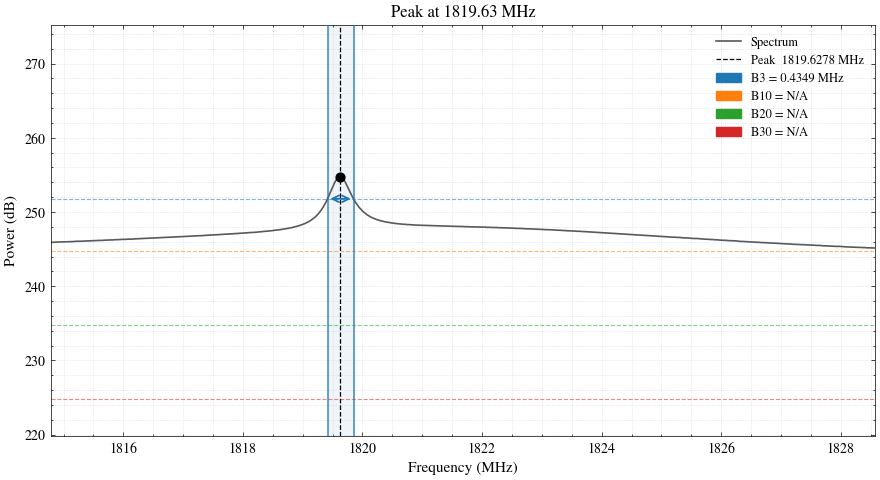

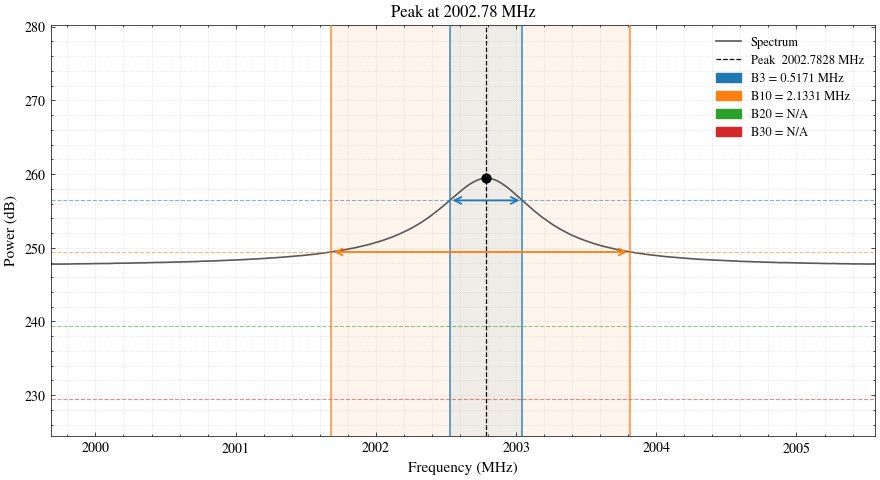

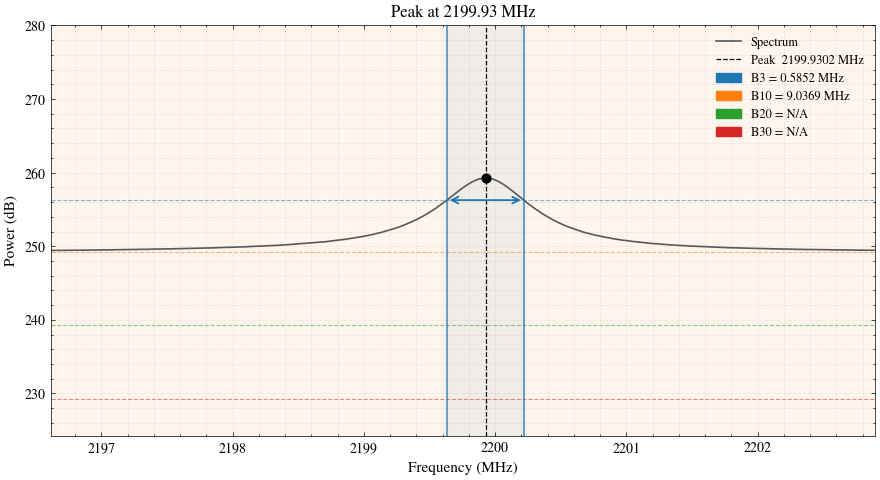

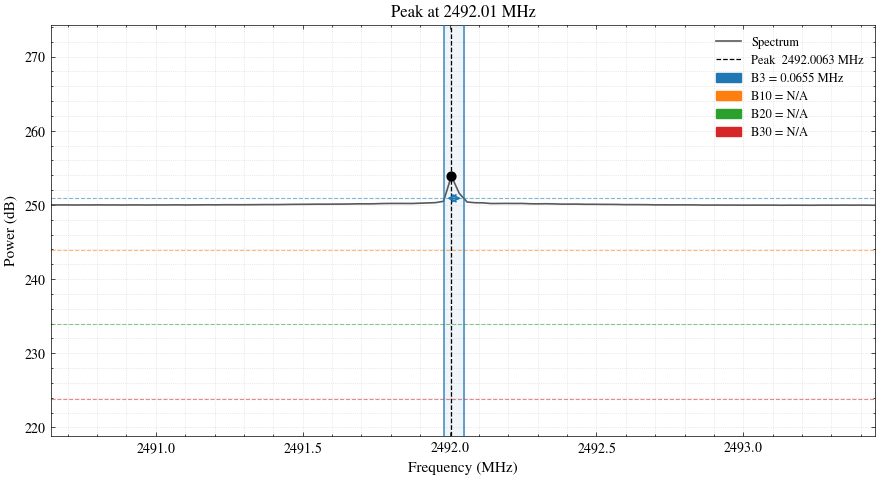

In [25]:
#
# Raw signal in dB
xdb_results = []
for i, peak in enumerate(peaks):

    # Peak channel index
    peak_index = int(peak)

    # Start and end frequencies for this peak (MHz)
    start_freq = windows_df["start_freq"].iloc[i]
    end_freq = windows_df["end_freq"].iloc[i]

    # Convert boundary frequencies to channel indices
    start_index = int(np.argmin(np.abs(frequency_mhz - start_freq)))
    end_index = int(np.argmin(np.abs(frequency_mhz - end_freq)))

    xdb = calculate_xdb_bandwidths(
        freq=frequency_mhz,
        power=mean_spectrum_db,
        peak_index=peak_index,
        start_index=start_index,
        end_index=end_index,
        )

        

    # With a diagnostic plot:
    xdb, ax = calculate_xdb_bandwidths(
        freq=frequency_mhz,
        power=mean_spectrum_db,
        peak_index=peak_index,
        start_index=start_index,
        end_index=end_index,levels=(3, 10, 20, 30),
        plot=True,
        freq_unit="MHz",
        title=f"Peak at {frequency_mhz[peak_index]:.2f} MHz"
    )
    
    xdb_results.append(xdb)


In [26]:
xdb_results_df = pd.DataFrame(xdb_results)
xdb_results_df

,B3_start,B3_end,B3,B10_start,B10_end,B10,B20_start,B20_end,B20,B30_start,B30_end,B30
0,1819.415072,1819.849930,0.434858,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2002.527504,2003.044594,0.517089,2001.680896,2003.814028,2.133132,NaN,NaN,NaN,NaN,NaN,NaN
2,2199.633075,2200.218279,0.585204,2195.298670,2204.335528,9.036858,NaN,NaN,NaN,NaN,NaN,NaN
3,2491.982759,2492.048298,0.065539,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:


def calculate_xdb_bandwidth_2(freq, power_db, peak_index, x_db):
    freq = np.asarray(freq, dtype=float)
    power_db = np.asarray(power_db, dtype=float)

    peak_power_db = power_db[peak_index]
    threshold_db = peak_power_db - x_db

    # Find the left crossing
    left = peak_index
    while left > 0 and power_db[left] > threshold_db:
        left -= 1

    # Find the right crossing
    right = peak_index
    while right < len(power_db) - 1 and power_db[right] > threshold_db:
        right += 1

    # Check whether both crossings were found
    if left == 0 or right == len(power_db) - 1:
        return np.nan, np.nan, np.nan

    # Interpolate crossing frequencies
    f_left = np.interp(
        threshold_db,
        [power_db[left], power_db[left + 1]],
        [freq[left], freq[left + 1]]
    )

    f_right = np.interp(
        threshold_db,
        [power_db[right], power_db[right - 1]],
        [freq[right], freq[right - 1]]
    )

    bandwidth = f_right - f_left

    return f_left, f_right, bandwidth


In [28]:
for i, peak in enumerate(peaks):
    f_left, f_right, B10 = calculate_xdb_bandwidth_2(
        freq=frequency_mhz,
        power_db=mean_spectrum_db,
        peak_index=peak,
        x_db=10
    )

    print(f"Peak {i + 1}: {frequency_mhz[peak]:.2f} MHz")
    print(f"B10 = {B10:.2f} MHz")

Peak 1: 1819.63 MHz
B10 = nan MHz
Peak 2: 2002.78 MHz
B10 = 2.13 MHz
Peak 3: 2199.93 MHz
B10 = 9.04 MHz
Peak 4: 2492.01 MHz
B10 = nan MHz


In [29]:
# calculate the spectral skewness for each peak 



def calculate_spectral_skewness(freq, power_linear, start_freq, end_freq):
    freq = np.asarray(freq, dtype=float)
    power = np.asarray(power_linear, dtype=float)

    # Select channels within the peak's window
    mask = (
        (freq >= start_freq) &
        (freq <= end_freq) &
        np.isfinite(freq) &
        np.isfinite(power)
    )

    f = freq[mask]
    p = power[mask]

    # Keep only positive power values
    valid = p > 0
    f = f[valid]
    p = p[valid]

    if len(f) < 3 or np.sum(p) <= 0:
        return np.nan

    # Weighted frequency mean
    mean_f = np.sum(p * f) / np.sum(p)

    # Weighted central moments
    variance = np.sum(p * (f - mean_f)**2) / np.sum(p)

    if variance <= 0:
        return np.nan

    std_f = np.sqrt(variance)
    moment_3 = np.sum(p * (f - mean_f)**3) / np.sum(p)

    skewness = moment_3 / std_f**3

    return skewness


In [30]:
"""
calculate_skewness.py
=====================
Spectral skewness for a single RFI peak.

Three complementary metrics:

1. Moment skewness (γ₁)
   Power-weighted third standardised central moment of the frequency distribution.
   γ₁ > 0 → right tail heavier (more power above the centroid)
   γ₁ < 0 → left tail heavier
   γ₁ = 0 → symmetric

2. Half-bandwidth skewness at each x-dB level
   sk_N = (hw_right − hw_left) / (hw_right + hw_left)   ∈ [−1, 1]
   Uses the crossing frequencies already computed by calculate_xdb_bandwidths.
   A depth profile (sk_3, sk_10, sk_20, sk_30) characterises the *shape* of
   the asymmetry, not just whether it exists.

3. Centroid offset (normalised)
   δ = (f_centroid − f_peak) / (B3 / 2)
   Positive → centroid is shifted right of the peak.
   Combines location and bandwidth into one dimensionless number.
"""



# ─────────────────────────────────────────────────────────────────────────────

def calculate_skewness(
    freq,
    power_detrended,
    peak_index,
    start_index,
    end_index,
    xdb_results=None,
    levels=(3, 10, 20, 30),
    plot=False,
    ax=None,
    freq_unit="MHz",
    title=None,
):
    """
    Compute spectral skewness metrics for one RFI peak.

    Parameters
    ----------
    freq             : 1-D array   Frequency axis.
    power_detrended  : 1-D array   Detrended LINEAR power (background ≈ 0).
                                   Power acts as the statistical weight.
    peak_index       : int         Index of the peak.
    start_index      : int         Left feature edge.
    end_index        : int         Right feature edge.
    xdb_results      : dict|None   Output of calculate_xdb_bandwidths — if
                                   supplied, half-bandwidth skewness is
                                   computed; otherwise only moment metrics.
    levels           : tuple       dB levels for half-bandwidth skewness.
                                   Must match those in xdb_results.
    plot             : bool        Produce a diagnostic plot.
    ax               : Axes|None
    freq_unit        : str
    title            : str|None

    Returns
    -------
    results : dict
        ``f_centroid``          Power-weighted mean frequency.
        ``f_peak``              Peak frequency.
        ``centroid_offset``     f_centroid − f_peak  (signed, same units as freq).
        ``centroid_offset_norm`` centroid_offset / (B3/2) if B3 available, else NaN.
        ``moment_variance``     Power-weighted frequency variance (σ²).
        ``moment_std``          σ  (spectral width).
        ``moment_skewness``     γ₁ — third standardised central moment.
        ``moment_kurtosis``     γ₂ — fourth standardised central moment − 3
                                (excess kurtosis; 0 for Gaussian).
        ``hw_left_{N}``         Left half-width at N dB  (f_peak − B{N}_start).
        ``hw_right_{N}``        Right half-width at N dB  (B{N}_end − f_peak).
        ``hw_skewness_{N}``     (hw_right − hw_left) / (hw_right + hw_left).
        ``hw_skewness_profile`` List of (level, hw_skewness) tuples, sorted by level.
    ax : Axes  (only when plot=True)
    """
    freq  = np.asarray(freq,  dtype=float)
    power = np.asarray(power_detrended, dtype=float)

    f_peak = float(freq[peak_index])

    # ── Signal window — clip negative residuals ───────────────────────────
    sig_f = freq [start_index : end_index + 1]
    sig_p = power[start_index : end_index + 1]
    sig_p = np.maximum(sig_p, 0.0)   # negative noise dips are not signal

    total_power = float(np.sum(sig_p))
    if total_power <= 0:
        raise ValueError("Total signal power ≤ 0 in the feature window. "
                         "Check start_index / end_index.")

    # ── Normalised weights ────────────────────────────────────────────────
    w = sig_p / total_power           # probability mass at each channel

    # ── Moment skewness ───────────────────────────────────────────────────
    f_centroid = float(np.sum(w * sig_f))                          # mean
    delta      = sig_f - f_centroid                                 # deviations

    mu2 = float(np.sum(w * delta ** 2))                            # variance
    mu3 = float(np.sum(w * delta ** 3))                            # 3rd moment
    mu4 = float(np.sum(w * delta ** 4))                            # 4th moment

    sigma   = np.sqrt(mu2) if mu2 > 0 else np.nan
    gamma1  = mu3 / mu2 ** 1.5 if mu2 > 0 else np.nan             # skewness
    gamma2  = mu4 / mu2 ** 2 - 3.0 if mu2 > 0 else np.nan        # excess kurtosis

    centroid_offset = f_centroid - f_peak

    results = {
        "f_centroid":           f_centroid,
        "f_peak":               f_peak,
        "centroid_offset":      centroid_offset,
        "centroid_offset_norm": np.nan,
        "moment_variance":      mu2,
        "moment_std":           sigma,
        "moment_skewness":      gamma1,
        "moment_kurtosis":      gamma2,
    }

    # ── Half-bandwidth skewness profile ───────────────────────────────────
    hw_skewness_profile = []
    if xdb_results is not None:
        for N in sorted(levels):
            f_lo = xdb_results.get(f"B{N}_start", np.nan)
            f_hi = xdb_results.get(f"B{N}_end",   np.nan)

            if np.isnan(f_lo) or np.isnan(f_hi):
                hw_l = hw_r = sk = np.nan
            else:
                hw_l = f_peak - f_lo        # left half-width
                hw_r = f_hi   - f_peak      # right half-width
                denom = hw_l + hw_r
                sk = (hw_r - hw_l) / denom if denom > 0 else 0.0

            results[f"hw_left_{N}"]     = hw_l
            results[f"hw_right_{N}"]    = hw_r
            results[f"hw_skewness_{N}"] = sk
            hw_skewness_profile.append((N, sk))

        results["hw_skewness_profile"] = hw_skewness_profile

        # Normalised centroid offset using B3 half-width
        B3 = xdb_results.get("B3", np.nan)
        if not np.isnan(B3) and B3 > 0:
            results["centroid_offset_norm"] = centroid_offset / (B3 / 2.0)

    if plot:
        ax = _make_plot(freq, power, peak_index, start_index, end_index,
                        f_centroid, sigma, results, xdb_results, levels,
                        freq_unit, title, ax)
        return results, ax

    return results 



# ─────────────────────────────────────────────────────────────────────────────
# Plot
# ─────────────────────────────────────────────────────────────────────────────

def _make_plot(freq, power, peak_index, start_index, end_index,
               f_centroid, sigma, results, xdb_results, levels,
               freq_unit, title, ax):
    # import matplotlib.pyplot as plt
    # import matplotlib.gridspec as gridspec

    has_profile = (xdb_results is not None and
                   "hw_skewness_profile" in results and
                   len(results["hw_skewness_profile"]) > 0)

    if ax is None:
        if has_profile:
            fig = plt.figure(figsize=(13, 5))
            gs  = gridspec.GridSpec(1, 2, width_ratios=[2.5, 1], figure=fig)
            ax  = fig.add_subplot(gs[0])
            ax2 = fig.add_subplot(gs[1])
        else:
            fig, ax = plt.subplots(figsize=(9, 5))
            ax2 = None
    else:
        fig = ax.get_figure()
        ax2 = None

    # ── Spectrum ──────────────────────────────────────────────────────────
    margin = max(1, int(0.15 * (end_index - start_index)))
    lo = max(0,         start_index - margin)
    hi = min(len(freq), end_index   + margin + 1)
    f_w = freq[lo:hi]
    p_w = power[lo:hi]

    ax.plot(f_w, p_w, color="0.35", lw=1.2, label="Spectrum", zorder=2)
    ax.fill_between(freq[start_index:end_index+1],
                    power[start_index:end_index+1],
                    alpha=0.10, color="#4C72B0", zorder=1)
    ax.axhline(0, color="0.6", lw=0.8, ls=":", zorder=1)

    f_peak = float(freq[peak_index])
    p_peak = float(power[peak_index])

    # Peak and centroid verticals
    ax.axvline(f_peak,     color="#D62728", lw=1.1, ls="-",  zorder=4,
               label=f"Peak      {f_peak:.4f} {freq_unit}")
    ax.axvline(f_centroid, color="#FF7F0E", lw=1.1, ls="--", zorder=4,
               label=f"Centroid  {f_centroid:.4f} {freq_unit}")

    # Moment std shading
    ax.axvspan(f_centroid - sigma, f_centroid + sigma,
               alpha=0.08, color="#FF7F0E", zorder=1,
               label=f"±1σ  ({sigma:.4f} {freq_unit})")

    # Annotation
    g1 = results['moment_skewness']
    g2 = results['moment_kurtosis']
    off = results['centroid_offset']
    off_n = results['centroid_offset_norm']
    ann = (
        f"Moment skewness γ₁  {g1:+.2f}\n"
        f"Excess kurtosis γ₂  {g2:+.2f}\n"
        f"Centroid offset     {off:+.2f} {freq_unit}\n"
        f"Norm. offset (B3/2) {off_n:+.2f}"
    )
    ax.text(0.97, 0.97, ann, transform=ax.transAxes,
            ha="right", va="top", fontsize=8.5, family="monospace",
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec="0.7", alpha=0.9))

    ax.set_xlabel(f"Frequency ({freq_unit})", fontsize=11)
    ax.set_ylabel("Detrended power (linear)", fontsize=11)
    ax.set_title(title or "Spectral Skewness", fontsize=12)
    ax.set_xlim(float(f_w[0]), float(f_w[-1]))
    ax.set_ylim(min(np.nanmin(p_w), 0) - 0.02*p_peak, p_peak*1.10)
    ax.legend(fontsize=8.5, loc="upper left", framealpha=0.85)
    ax.grid(True, ls=":", lw=0.5, alpha=0.5)

    # ── Half-bandwidth skewness profile ───────────────────────────────────
    if ax2 is not None and has_profile:
        profile = results["hw_skewness_profile"]
        lvls    = [p[0] for p in profile]
        sks     = [p[1] for p in profile]
        colours = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

        for i, (lv, sk) in enumerate(zip(lvls, sks)):
            c = colours[i % len(colours)]
            ax2.barh(lv, sk, height=3.5, color=c, alpha=0.75, zorder=3)
            ax2.text(sk + 0.01 * np.sign(sk) if not np.isnan(sk) else 0,
                     lv, f"{sk:+.3f}" if not np.isnan(sk) else "N/A",
                     va="center", ha="left" if (sk >= 0 or np.isnan(sk)) else "right",
                     fontsize=8.5, family="monospace")

        ax2.axvline(0, color="k", lw=0.9, ls="--", zorder=2)
        ax2.set_xlabel("Half-bandwidth skewness\n(−1 = left, +1 = right)", fontsize=9)
        ax2.set_ylabel("dB level", fontsize=9)
        ax2.set_title("Skewness profile", fontsize=10)
        ax2.set_yticks(lvls)
        ax2.set_yticklabels([f"B{l}" for l in lvls])
        ax2.set_xlim(-1.05, 1.05)
        ax2.grid(True, axis="x", ls=":", lw=0.5, alpha=0.5)
        ax2.invert_yaxis()

    fig.tight_layout()
    return ax

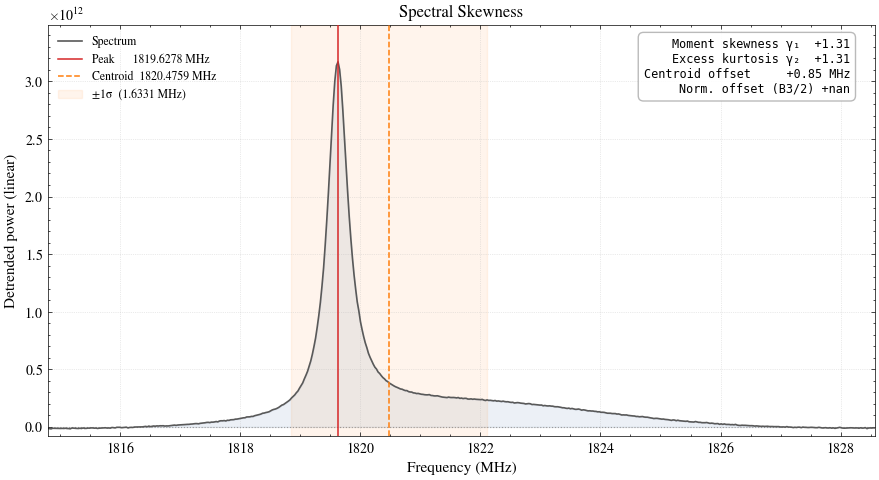

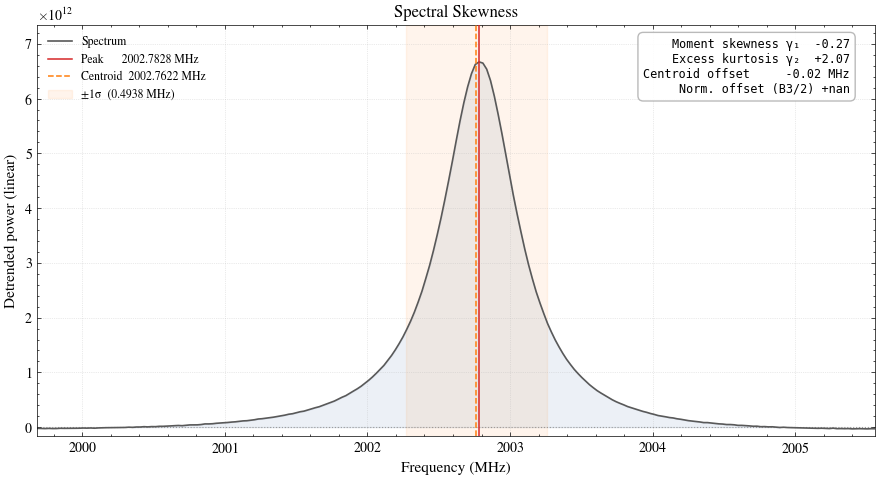

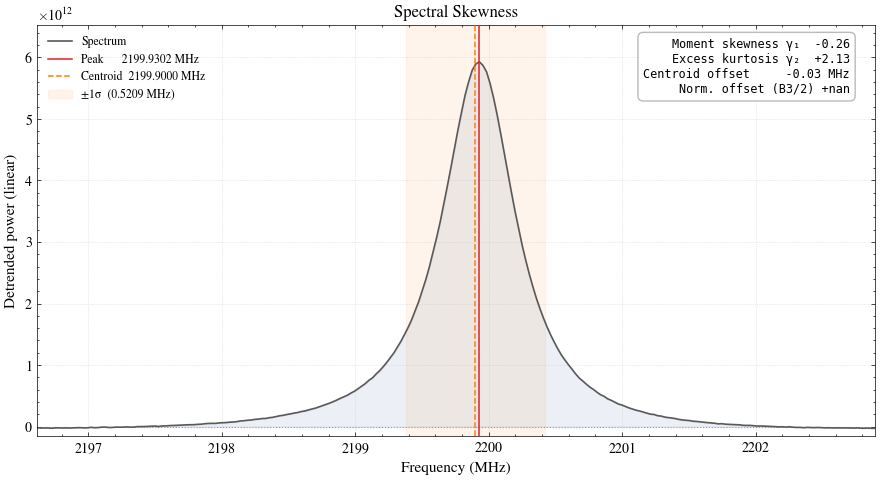

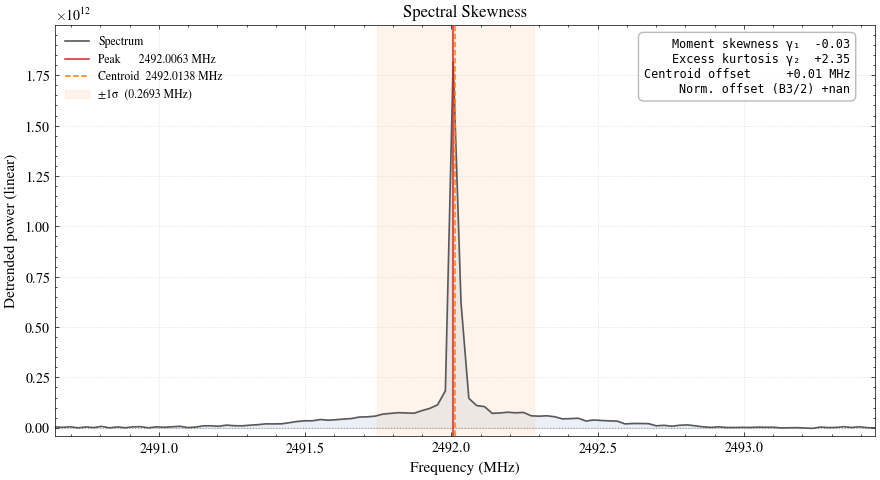

In [31]:
# Raw signal in dB

skewness_results = []
for i, peak in enumerate(peaks):

    # Peak channel index
    peak_index = int(peak)

    # Start and end frequencies for this peak (MHz)
    start_freq = windows_df["start_freq"].iloc[i]
    end_freq = windows_df["end_freq"].iloc[i]

    # Convert boundary frequencies to channel indices
    start_index = int(np.argmin(np.abs(frequency_mhz - start_freq)))
    end_index = int(np.argmin(np.abs(frequency_mhz - end_freq)))


    skewness = calculate_skewness(
        freq = frequency_mhz,
        power_detrended = spectrum_corrected,
        peak_index=peak_index,
        start_index=start_index,
        end_index=end_index,
        xdb_results=None,
        levels=(3, 10, 20, 30),
        plot=True,
        ax=None,
        freq_unit="MHz",
        title=None,
    )

 # Extract the dictionary if the function returns (dictionary, plot axis)
    skewness_dict = skewness[0] if isinstance(skewness, tuple) else skewness

    # Add peak information
    skewness_dict["peak_index"] = peak_index
    skewness_dict["start_freq"] = start_freq
    skewness_dict["end_freq"] = end_freq

    skewness_results.append(skewness_dict)

In [32]:

# Convert the list of dictionaries into a DataFrame
skewness_df = pd.DataFrame(skewness_results)

display(skewness_df)

,f_centroid,f_peak,centroid_offset,centroid_offset_norm,moment_variance,moment_std,moment_skewness,moment_kurtosis,peak_index,start_freq,end_freq
0,1820.475938,1819.627762,0.848176,NaN,2.667134,1.633136,1.306576,1.308071,1008,1816.370010,1826.997757
1,2002.762170,2002.782822,-0.020651,NaN,0.243827,0.493788,-0.265722,2.072347,7867,2000.352859,2004.892349
2,2199.899952,2199.930191,-0.030239,NaN,0.271382,0.520943,-0.256935,2.127466,15250,2197.340012,2202.173233
3,2492.013815,2492.006302,0.007513,NaN,0.072501,0.269259,-0.030453,2.350262,26188,2490.964890,2493.127823


In [33]:
# create a master dataframe that combines the SNR, x-dB bandwidths, and skewness results for each peak
master_df = pd.concat(
    [
        results_obw_99_df[["peak_index", "peak_freq", "peak_power", "obw_99", "fwhm_khz", "R_obw_fwhm"]],
        snr_results_df[["snr_ratio"]],
        xdb_results_df[["B3", "B10", "B20", "B30"]],
        skewness_df[["moment_skewness", "moment_kurtosis", "f_centroid"]]
    ],
    axis=1
)

display(master_df)

,peak_index,peak_freq,peak_power,obw_99,fwhm_khz,R_obw_fwhm,snr_ratio,B3,B10,B20,B30,moment_skewness,moment_kurtosis,f_centroid
0,1008,1819.627762,3.168866e+12,8.476603,436.758531,19407.985374,2.502306,0.434858,NaN,NaN,NaN,1.306576,1.308071,1820.475938
1,7867,2002.782822,6.670186e+12,3.192414,625.903365,5100.490005,3.210891,0.517089,2.133132,NaN,NaN,-0.265722,2.072347,2002.762170
2,15250,2199.930191,5.925452e+12,3.381005,655.177736,5160.438705,3.129979,0.585204,9.036858,NaN,NaN,-0.256935,2.127466,2199.899952
3,26188,2492.006302,1.816093e+12,1.702865,35.284548,48260.923653,0.380069,0.065539,NaN,NaN,NaN,-0.030453,2.350262,2492.013815
